In [2]:
from typing import List, TypedDict
import re

from langchain_ollama import ChatOllama, OllamaEmbeddings
from langchain_chroma import Chroma
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.document_loaders import PyPDFLoader
from langchain_core.documents import Document
from langchain_core.prompts import ChatPromptTemplate
from pydantic import BaseModel

from langgraph.graph import StateGraph, END, START
from dotenv import load_dotenv

load_dotenv()

C:\Users\user\AppData\Local\Temp\ipykernel_44220\1463615369.py:7: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyPDFLoader


False

In [3]:
docs = PyPDFLoader("../documents/MilanRaiMERN.pdf").load()

In [4]:
chunks = RecursiveCharacterTextSplitter(chunk_size=400, chunk_overlap=50).split_documents(docs)

In [5]:
for d in chunks: 
    d.page_content = d.page_content.encode("utf-8", "ignore").decode("utf-8", "ignore")

In [6]:
embeddings = OllamaEmbeddings(model="bge-m3")

In [7]:
vector_store = Chroma.from_documents(
    documents=docs,
    embedding=embeddings,
    persist_directory="../ha_db"
)

In [8]:
retriever = vector_store.as_retriever(search_type="similarity", search_kwargs={'k': 4})

In [9]:
llm = ChatOllama(model="llama3.2")

In [19]:
UPPER_TH = 0.7
LOWER_TH = 0.3

In [20]:
class State(TypedDict): 
    question: str 
    docs: List[Document]

    good_docs : List[Document] #evaluation score greater than 0.3
    verdict: str 
    reason: str

    strips: List[str]
    kept_strips: List[str]
    refined_context: str

    answer: str

In [11]:
def retrieve(state: State) -> State: 
    q = state['question']
    return{'docs': retriever.invoke(q)}

In [12]:
# Sentence level decompose
def decompose_to_sentences(text: str) -> List[str]:
    text = re.sub(r"\s+", " ", text).strip()
    sentences = re.split(r"(?<=[.!?])\s+", text)
    return [s.strip() for s in sentences if len(s.strip()) > 20]

In [60]:

def eval_each_doc_node(state: State) -> State:

    q = state["question"]

    score: List[float] = []
    reasons: List[str] = []
    good: List[Document] = []

    for d in state["docs"]:

        out = doc_eval_chain.invoke({
            "question": q,
            "chunk": d.page_content
        })

        score.append(out.score)
        reasons.append(out.reason)

        if out.score > LOWER_TH:
            good.append(d)

    # CORRECT
    if any(s > UPPER_TH for s in score):
        return {
            "good_docs": good,
            "score": score,
            "reasons": reasons,
            "verdict": "CORRECT",
            "reason": f"At least one retrieved chunk scored > {UPPER_TH}"
        }

    # INCORRECT
    if len(score) > 0 and all(s < LOWER_TH for s in score):
        return {
            "good_docs": [],
            "score": score,
            "reasons": reasons,
            "verdict": "INCORRECT",
            "reason": "No chunk was sufficiently relevant."
        }

    # AMBIGUOUS
    return {
        "good_docs": good,
        "score": score,
        "reasons": reasons,
        "verdict": "AMBIGUOUS",
        "reason": f"No chunk scored > {UPPER_TH}, but not all were < {LOWER_TH}. Mixed relevance signals."
    }


In [41]:
#Filter (LLM judge)
class KeepOrDrop(BaseModel): 
    keep: bool

    

In [42]:
filter_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system", 
            "You are a strict relevance filter. \n"
            "Return keep=true only if the sentence directly helps answer the question. \n"
            "Use ONLY the sentence. Output JSON only."
        ),
        ("human", "Question: {question}\n\nSentence:\n{sentence}")
    ]
)

filter_chain = filter_prompt | llm.with_structured_output(KeepOrDrop)

In [43]:
# Refining (Decompose -> Filter -> Recompose)
def refine(state: State) -> State: 
    q = state['question']

    #Combine retrieved docs into one context string
    context = "\n\n".join(d.page_content for d in state['good_docs']).strip()

    #Decomposition: context -> sentence strips
    strips = decompose_to_sentences(context)

    #Filter: keeps only relevant strips
    kept: List[str] = []

    for s in strips: 
        if filter_chain.invoke({"question": q, "sentence": s}).keep:
            kept.append(s)
    #Recompose: glue kept strips back together (internal knowledge)
    refined_context = "\n".join(kept).strip()

    return{
        "strips": strips,
        "kept_strips": kept, 
        "refined_context": refined_context
    }

In [44]:
answer_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "You are a helpful ML tutor. Answer ONLY using the provided refined bullets.\n"
            "If the bullets are empty or insufficient, say: 'I don't know based on the provided books.'",
        ),
        ("human", "Question: {question}\n\nRefined context:\n{refined_context}"),
    ]
)

def generate(state: State) -> State:
    out = (answer_prompt | llm).invoke({"question": state["question"], "refined_context": state['refined_context']})
    return {"answer": out.content}


In [45]:
def fail_node(state: State) -> State: 
    return {"answer": f"FAIL: {state['reasons']}"}

def ambiguous_node(state: State) -> State:
    return {"answer": f"Ambiguous: {state['reason']}"}

def route_after_eval(state: State) -> str: 
    if state['verdict'] == "CORRECT": 
        return "refine"
    elif state['verdict'] == "INCORRECT": 
        return "fail_node"
    else: 
        return "ambiguous"

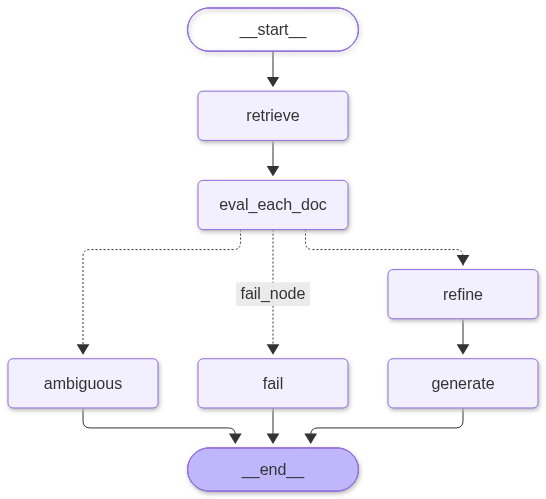

In [46]:
g = StateGraph(State)
g.add_node("retrieve", retrieve)
g.add_node("refine", refine)
g.add_node("generate", generate)
g.add_node("eval_each_doc", eval_each_doc_node)
g.add_node("fail", fail_node)
g.add_node("ambiguous", ambiguous_node)

g.add_edge(START, "retrieve")
g.add_edge("retrieve", "eval_each_doc")

g.add_conditional_edges("eval_each_doc", route_after_eval, {
    "refine": "refine",
    "fail_node": "fail",
    "ambiguous": "ambiguous",
})

g.add_edge("refine", "generate")
g.add_edge("generate", END)
g.add_edge("fail", END)
g.add_edge("ambiguous", END)

app = g.compile()
app

In [47]:
res = app.invoke({
    "question": "Which Skill does milan know",
    "docs": [],
    "strips": [],
    "kept_strips": [],
    "refined_context": "",
    "answer": ""
})
print(res["answer"])

Based on the provided refined context, here are the skills that Milan seems to know:

• Frontend: 
  • React.js
  • Redux Toolkit
  • React Router
  • React Hooks
  • HTML5
  • CSS3
  • Tailwind CSS

• Backend: 
  • Node.js
  • Express.js
  • RESTful APIs
  • FastAPI

• Databases: 
  • MongoDB

• Generative AI: 
  • LLMs
  • RAG
  • LangChain
  • LangGraph
  • Ollama

• Development Tools: 
  • Git
  • GitHub
  • Docker
  • Postman
  • VS Code


In [48]:
res = app.invoke({
    "question": "Who is Milan",
    "docs": [],
    "strips": [],
    "kept_strips": [],
    "refined_context": "",
    "answer": ""
})
print(res["answer"])


I don't know based on the provided books.


In [53]:
for doc in res["docs"]:
    print(doc.page_content)

MILAN RAI
MERN Stack Developer
Morang, Nepal | +977-9823459115 | milansampang14@gmail.com | linkedin.com/in/milanrai14 | github.com/milanrai14
PROFESSIONAL SUMMARY
MERN Stack Developer focused on building full-stack web applications with React.js, Node.js, Express.js, TypeScript, and
MongoDB. Experienced in designing RESTful APIs, integrating frontend and backend services, and developing database-
driven applications, with additional experience in Python-based AI development using FastAPI, LangChain, and Ollama.
Interested in building scalable, maintainable products that solve real-world problems.
TECHNICAL SKILLS
Programming JavaScript (ES6+), TypeScript, Python, Java, SQL
Frontend React.js, Redux Toolkit, React Router, React Hooks, HTML5, CSS3, Tailwind CSS
Backend Node.js, Express.js, RESTful APIs, FastAPI
Databases MongoDB, MySQL
Generative AI LLMs, RAG, LangChain, LangGraph, Ollama
Tools Git, GitHub, Docker, Postman, VS Code
PROJECTS
Digital Kirana Pasal
MongoDB, Express.js, React

In [59]:
res = app.invoke(
    {
        "question": "What are attention mechanisms and why are they important in current models?",
        "docs": [],
        "good_docs": [],
        "verdict": "",
        "reasons": "",
        "strips": [],
        "kept_strips": [],
        "refined_context": "",
        "answer": "",
    }
)

print("VERDICT:", res["verdict"])
print("REASON:", res["reason"])
print("\nOUTPUT:\n", res["answer"])

KeyError: 'reasons'